# SQD for N₂: classical vs Qiskit Aer vs PennyLane (ideal, noisy, random control)
All sampling backends feed the **same** SQD solver (`qiskit-addon-sqd`) on the **same** N₂ active space, so the energies are directly comparable.

| Role | Method |
|---|---|
| Non-quantum references | HF, CCSD, exact CASCI/FCI (PySCF) |
| Sampler 1 / 2 | Qiskit Aer, noiseless / noisy (`FakeSherbrooke` noise model) |
| Sampler 3 / 4 | PennyLane `lightning.qubit`, noiseless / noisy (Pauli-trajectory noise using FakeSherbrooke average error rates) |
| Control | Uniform random bitstrings (no circuit at all) |
| Optional | Real IBM hardware through PennyLane (`RUN_HARDWARE`, off by default, untested here) |

> IBM RXN for Chemistry predicts chemical reactions and cannot compute electronic energies, so it is not used; PySCF is the non-quantum reference.
> The PennyLane noisy sampler is a simplified noise model (gate depolarizing + readout flips), not the full Aer device model, so differences between the two noisy samplers are expected.

Uncomment the next line on Colab / a fresh environment.

In [1]:
pip install  pyscf ffsim qiskit qiskit-aer qiskit-ibm-runtime qiskit-addon-sqd pennylane pennylane-lightning matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 32.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 784.5/784.5 kB 21.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 49.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 39.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 13.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 48.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 25.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 26.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 54.3 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0.post0
    Uninstalling python-dateutil-2.9.0.post0:
      Successfully un

In [1]:
import time, os, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyscf, pyscf.cc, pyscf.mcscf, pyscf.ao2mo
import ffsim, pennylane as qml
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit_addon_sqd.counts import counts_to_arrays
from qiskit_addon_sqd.configuration_recovery import recover_configurations
from qiskit_addon_sqd.fermion import bitstring_matrix_to_ci_strs, solve_fermion
from qiskit_addon_sqd.subsampling import postselect_and_subsample
warnings.filterwarnings("ignore")

# ---- settings ----
N_ACTIVE     = 7        # active spatial orbitals (7 -> 14 qubits; keeps degenerate pi pairs together)
N_REPS       = 2        # UCJ layers
SHOTS_IDEAL  = 10000   # noiseless samplers + random control
SHOTS_NOISY  = 1000    # noisy samplers (slow on CPU)
SEED         = 24
RUN_HARDWARE = False    # True -> also sample real IBM hardware via PennyLane (needs IBM_QUANTUM_TOKEN env var)
SHOTS_HW     = 4000

## 1. Classical (non-quantum) baselines

In [2]:
mol = pyscf.gto.Mole()
mol.build(atom=[["N", (0, 0, 0)], ["N", (1.0, 0, 0)]], basis="6-31g", symmetry="Dooh", verbose=0)
n_frozen = 2
active_space = range(n_frozen, n_frozen + N_ACTIVE)
scf = pyscf.scf.RHF(mol).run()
norb = len(active_space)
n_electrons = int(sum(scf.mo_occ[active_space]))
nea = (n_electrons + mol.spin) // 2
neb = (n_electrons - mol.spin) // 2
cas = pyscf.mcscf.CASCI(scf, norb, (nea, neb))
mo = cas.sort_mo(active_space, base=0)
hcore, nuc = cas.get_h1cas(mo)
eri = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), norb)
exact_energy = cas.run(mo).e_tot
ccsd = pyscf.cc.CCSD(scf, frozen=[i for i in range(mol.nao_nr()) if i not in active_space]).run()
dm1 = cas.fcisolver.make_rdm1(cas.ci, norb, (nea, neb))
exact_occ = np.diag(dm1)          # exact spatial-orbital occupancies (0..2)
classical = {"HF": scf.e_tot, "CCSD": ccsd.e_tot, "Exact CASCI/FCI": exact_energy}
print(f"{n_electrons} electrons in {norb} orbitals -> {2*norb} qubits;  full CI dimension = {math.comb(norb,nea)*math.comb(norb,neb)}")
for k, v in classical.items(): print(f"  {k:18s}{v:.6f} Ha")

10 electrons in 7 orbitals -> 14 qubits;  full CI dimension = 441
  HF                -108.835237 Ha
  CCSD              -108.900003 Ha
  Exact CASCI/FCI   -108.901187 Ha


## 2. Circuit (HF reference + UCJ ansatz from CCSD amplitudes)

In [3]:
aa = [(p, p + 1) for p in range(norb - 1)]
ab = [(p, p) for p in range(0, norb, 4)]
ucj = ffsim.UCJOpSpinBalanced.from_t_amplitudes(t2=ccsd.t2, t1=ccsd.t1, n_reps=N_REPS, interaction_pairs=(aa, ab))
q = QuantumRegister(2 * norb, "q")
circuit = QuantumCircuit(q)
circuit.append(ffsim.qiskit.PrepareHartreeFockJW(norb, (nea, neb)), q)
circuit.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj), q)
circuit.measure_all()
nq = 2 * norb

## 3. Samplers

### 3a. Qiskit Aer (noiseless and noisy)

In [4]:
fake = FakeSherbrooke()

def aer_ideal():
    sim = AerSimulator()
    pm = generate_preset_pass_manager(optimization_level=3, backend=sim); pm.pre_init = ffsim.qiskit.PRE_INIT
    isa = pm.run(circuit)
    t = time.time(); counts = sim.run(isa, shots=SHOTS_IDEAL, seed_simulator=SEED).result().get_counts()
    return counts, dict(depth=isa.depth(), two_q=sum(v for k, v in isa.count_ops().items() if k in ("cx","ecr","rxx","ryy","cp")), time=time.time()-t)

def aer_noisy():
    sim = AerSimulator(noise_model=NoiseModel.from_backend(fake))
    pm = generate_preset_pass_manager(optimization_level=3, backend=fake); pm.pre_init = ffsim.qiskit.PRE_INIT
    isa = pm.run(circuit)
    t = time.time(); counts = sim.run(isa, shots=SHOTS_NOISY, seed_simulator=SEED).result().get_counts()
    return counts, dict(depth=isa.depth(), two_q=isa.count_ops().get("ecr", 0), time=time.time()-t)

### 3b. PennyLane
The Qiskit circuit is transpiled to `rz, sx, x, cx` (all-to-all connectivity) and mapped gate-by-gate to PennyLane operations. The **noisy** version runs one trajectory per shot with random Pauli errors after each gate (error rates = FakeSherbrooke averages) plus readout bit-flips.

In [5]:
BASIS = ["rz", "sx", "x", "cx"]

def to_pl_ops(qc):
    ops, used = [], set()
    for inst in qc.data:
        n = inst.operation.name
        qs = [qc.find_bit(x).index for x in inst.qubits]
        if n in ("barrier", "measure"): continue
        if   n == "rz": ops.append(("rz", qs, float(inst.operation.params[0])))
        elif n == "sx": ops.append(("sx", qs, None))
        elif n == "x":  ops.append(("x", qs, None))
        elif n == "cx": ops.append(("cx", qs, None))
        else: raise ValueError(f"unsupported gate {n}")
        used.update(qs)
    return ops, sorted(used)

def build_op(o):
    n, qs, p = o
    return {"rz": lambda: qml.RZ(p, wires=qs[0]), "sx": lambda: qml.SX(wires=qs[0]),
            "x": lambda: qml.PauliX(qs[0]), "cx": lambda: qml.CNOT(wires=qs)}[n]()

pm_pl = generate_preset_pass_manager(optimization_level=3, basis_gates=BASIS); pm_pl.pre_init = ffsim.qiskit.PRE_INIT
isa_pl = pm_pl.run(circuit)
ops_spec, used = to_pl_ops(isa_pl)
assert used == list(range(nq)), used
base_ops = [build_op(o) for o in ops_spec]
pl_stats = dict(depth=isa_pl.depth(), two_q=isa_pl.count_ops().get("cx", 0))
print("PennyLane circuit:", dict(isa_pl.count_ops()))

def to_counts(bits):                       # bits: (shots, nq) with column i = qubit i ; qiskit strings are little-endian
    strs = ["".join(map(str, r[::-1])) for r in bits.astype(int)]
    out = {}
    for s in strs: out[s] = out.get(s, 0) + 1
    return out

def pl_ideal():
    dev = qml.device("lightning.qubit", wires=nq, shots=SHOTS_IDEAL, seed=SEED)
    tape = qml.tape.QuantumScript(base_ops, [qml.sample(wires=range(nq))], shots=SHOTS_IDEAL)
    t = time.time(); (bits,) = qml.execute([tape], dev);
    return to_counts(np.array(bits)), dict(pl_stats, time=time.time()-t)

# FakeSherbrooke average error rates
tgt = fake.target
e2 = np.median([p.error for p in tgt["ecr"].values() if p is not None and p.error is not None])
e1 = np.median([p.error for k, p in tgt["sx"].items() if p is not None and p.error is not None])
er = np.median([p.error for p in tgt["measure"].values() if p is not None and p.error is not None])
print(f"median FakeSherbrooke error rates  2q={e2:.4f}  1q={e1:.5f}  readout={er:.4f}")
PAULIS = [qml.Identity, qml.PauliX, qml.PauliY, qml.PauliZ]

def pl_noisy():
    rng = np.random.default_rng(SEED)
    ng = len(ops_spec)
    p_gate = np.array([e2 if o[0] == "cx" else (e1 if o[0] in ("sx", "x") else 0.0) for o in ops_spec])
    tapes = []
    for _ in range(SHOTS_NOISY):
        hit = np.nonzero(rng.random(ng) < p_gate)[0]
        ops, last = [], 0
        for g in hit:
            ops += base_ops[last:g+1]; last = g + 1
            qs = ops_spec[g][1]
            while True:                                   # random non-identity Pauli on the gate's qubits
                ch = rng.integers(0, 4, size=len(qs))
                if ch.any(): break
            ops += [PAULIS[c](wires=w) for c, w in zip(ch, qs) if c]
        ops += base_ops[last:]
        tapes.append(qml.tape.QuantumScript(ops, [qml.sample(wires=range(nq))], shots=1))
    dev = qml.device("lightning.qubit", wires=nq, seed=SEED)
    t = time.time(); res = qml.execute(tapes, dev)
    bits = np.array([np.array(r).reshape(-1) for r in res])
    flip = rng.random(bits.shape) < er                   # readout error
    bits = np.where(flip, 1 - bits, bits)
    return to_counts(bits), dict(pl_stats, time=time.time()-t)

PennyLane circuit: {'rz': 547, 'sx': 478, 'cx': 188, 'measure': 14, 'x': 1, 'barrier': 1}
median FakeSherbrooke error rates  2q=0.0078  1q=0.00024  readout=0.0198


### 3c. Control: uniform random bitstrings (no quantum circuit)

In [6]:
def random_control():
    rng = np.random.default_rng(SEED)
    t = time.time(); bits = rng.integers(0, 2, size=(SHOTS_IDEAL, nq))
    return to_counts(bits), dict(depth=0, two_q=0, time=time.time()-t)

## 4. SQD solver (identical for every sampler)

In [7]:
def sqd(counts, iterations=5, n_batches=5, samples_per_batch=300):
    rng = np.random.default_rng(SEED)
    bs_full, probs_full = counts_to_arrays(counts)
    e_hist = np.zeros((iterations, n_batches)); avg_occ = None; dims = []
    for i in range(iterations):
        if avg_occ is None: bs, pr = bs_full, probs_full
        else: bs, pr = recover_configurations(bs_full, probs_full, avg_occ, nea, neb, rand_seed=rng)
        batches = postselect_and_subsample(bs, pr, hamming_right=nea, hamming_left=neb,
                                           samples_per_batch=samples_per_batch, num_batches=n_batches, rand_seed=rng)
        occs = []
        for j in range(n_batches):
            sa, sb = bitstring_matrix_to_ci_strs(batches[j])
            if i == iterations - 1: dims.append(len(sa) * len(sb))
            e, _, o, _ = solve_fermion(batches[j], hcore, eri, open_shell=False, spin_sq=0, max_cycle=300)
            e_hist[i, j] = e + nuc; occs.append(o)
        avg_occ = tuple(np.mean(occs, axis=0))
    return e_hist, np.array(avg_occ[0]) + np.array(avg_occ[1]), int(np.mean(dims))

def valid_fraction(counts):
    tot = sum(counts.values())
    return sum(c for b, c in counts.items() if b[:norb].count("1") == neb and b[norb:].count("1") == nea) / tot

## 5. Run every sampler (the two noisy ones take several minutes on CPU)

In [8]:
samplers = {"Aer noiseless": aer_ideal, "PennyLane noiseless": pl_ideal,
            "Aer noisy": aer_noisy, "PennyLane noisy": pl_noisy, "Random bitstrings": random_control}
counts_d, meta_d = {}, {}
for name, fn in samplers.items():
    print(f"sampling: {name} ...", flush=True)
    counts_d[name], meta_d[name] = fn()
    print(f"   {meta_d[name]['time']:.1f}s, depth {meta_d[name]['depth']}, unique bitstrings {len(counts_d[name])}")

sampling: Aer noiseless ...
   0.1s, depth 62, unique bitstrings 5
sampling: PennyLane noiseless ...
   0.1s, depth 181, unique bitstrings 6
sampling: Aer noisy ...
   302.1s, depth 239, unique bitstrings 421
sampling: PennyLane noisy ...
   39.2s, depth 181, unique bitstrings 417
sampling: Random bitstrings ...
   0.0s, depth 0, unique bitstrings 7509


### Optional: real IBM hardware through PennyLane (`RUN_HARDWARE = True`)
Not executed in this notebook run (no account here). It routes the circuit to the device's coupling map, maps it to PennyLane ops with the same converter, and samples through `qml.device('qiskit.remote')`. Treat as a starting point and expect to adjust it for your plugin version.

In [9]:
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(token=os.environ["IBM_QUANTUM_TOKEN"])      # never hardcode the token
    hw = service.least_backend(operational=True, simulator=False) if hasattr(service, "least_backend") else service.least_busy(operational=True, simulator=False)
    pm_hw = generate_preset_pass_manager(optimization_level=3, backend=hw, basis_gates=BASIS, coupling_map=hw.coupling_map)
    pm_hw.pre_init = ffsim.qiskit.PRE_INIT
    isa_hw = pm_hw.run(circuit)
    spec_hw, used_hw = to_pl_ops(isa_hw)
    ops_hw = [build_op(o) for o in spec_hw]
    dev = qml.device("qiskit.remote", wires=hw.num_qubits, backend=hw, shots=SHOTS_HW)
    @qml.qnode(dev)
    def hw_circuit():
        for op in ops_hw: qml.apply(op)
        return qml.sample(wires=used_hw)
    t = time.time(); bits = np.array(hw_circuit()).reshape(SHOTS_HW, -1)
    # map physical qubits back to logical ordering using the final layout, then:  counts_d["IBM hardware (PennyLane)"] = to_counts(...)
    print("hardware samples collected:", bits.shape, f"{time.time()-t:.0f}s  (map physical->logical qubits before SQD)")
else:
    print("Hardware run skipped (RUN_HARDWARE = False).")

Hardware run skipped (RUN_HARDWARE = False).


## 6. Run SQD on every sampler's output

In [10]:
res = {}
for name, c in counts_d.items():
    print(f"SQD on: {name} ...", flush=True)
    eh, occ, dim = sqd(c)
    res[name] = dict(e_hist=eh, occ=occ, dim=dim, valid=valid_fraction(c), unique=len(c),
                     unique_valid=sum(1 for b in c if b[:norb].count("1") == neb and b[norb:].count("1") == nea))
    print(f"   final E = {eh[-1].min():.6f} Ha")

SQD on: Aer noiseless ...
   final E = -108.866422 Ha
SQD on: PennyLane noiseless ...
   final E = -108.866422 Ha
SQD on: Aer noisy ...
   final E = -108.901166 Ha
SQD on: PennyLane noisy ...
   final E = -108.901187 Ha
SQD on: Random bitstrings ...
   final E = -108.901187 Ha


## 7. Tables

In [11]:
CHEM = 1.6e-3
rows = [(k, v) for k, v in classical.items()] + [(f"SQD + {k}", r["e_hist"][-1].min()) for k, r in res.items()]
t_energy = pd.DataFrame(rows, columns=["Method", "Energy (Ha)"])
t_energy["Error vs FCI (Ha)"] = (t_energy["Energy (Ha)"] - exact_energy).abs()
t_energy["Error (mHa)"] = t_energy["Error vs FCI (Ha)"] * 1e3
t_energy["Within chemical accuracy (1.6 mHa)"] = np.where(t_energy["Error vs FCI (Ha)"] < CHEM, "yes", "no")
display(t_energy.style.format({"Energy (Ha)": "{:.6f}", "Error vs FCI (Ha)": "{:.2e}", "Error (mHa)": "{:.3f}"}).hide(axis="index"))

full_ci = math.comb(norb, nea) * math.comb(norb, neb)
t_diag = pd.DataFrame([{
    "Sampler": k, "Shots": sum(counts_d[k].values()), "Circuit depth": meta_d[k]["depth"], "2q gates": meta_d[k]["two_q"],
    "Sampling time (s)": round(meta_d[k]["time"], 2), "Valid-particle-number shots": f"{r['valid']:.1%}",
    "Unique bitstrings": r["unique"], "Unique valid": r["unique_valid"],
    f"SQD subspace dim (full CI = {full_ci})": r["dim"]} for k, r in res.items()])
display(t_diag.style.hide(axis="index"))

t_iter = pd.DataFrame({k: [abs(e.min() - exact_energy) for e in r["e_hist"]] for k, r in res.items()})
t_iter.index.name = "SQD iteration"
display(t_iter.style.format("{:.2e}"))
t_energy.to_csv("table_energies.csv", index=False); t_diag.to_csv("table_sampler_diagnostics.csv", index=False); t_iter.to_csv("table_convergence.csv")

Method,Energy (Ha),Error vs FCI (Ha),Error (mHa),Within chemical accuracy (1.6 mHa)
HF,-108.835237,6.60e-02,65.951,no
CCSD,-108.900003,1.18e-03,1.184,yes
Exact CASCI/FCI,-108.901187,0.00e+00,0.000,yes
SQD + Aer noiseless,-108.866422,3.48e-02,34.765,no
SQD + PennyLane noiseless,-108.866422,3.48e-02,34.765,no
SQD + Aer noisy,-108.901166,2.17e-05,0.022,yes
SQD + PennyLane noisy,-108.901187,1.08e-10,0.000,yes
SQD + Random bitstrings,-108.901187,1.08e-10,0.000,yes


Sampler,Shots,Circuit depth,2q gates,Sampling time (s),Valid-particle-number shots,Unique bitstrings,Unique valid,SQD subspace dim (full CI = 441)
Aer noiseless,10000,62,182,0.100000,100.0%,5,5,9
PennyLane noiseless,10000,181,188,0.090000,100.0%,6,6,9
Aer noisy,1000,239,188,302.080000,32.9%,421,50,400
PennyLane noisy,1000,181,188,39.190000,32.4%,417,52,441
Random bitstrings,10000,0,0,0.050000,3.0%,7509,214,441


,Aer noiseless,PennyLane noiseless,Aer noisy,PennyLane noisy,Random bitstrings
SQD iteration,,,,,
0,3.48e-02,3.48e-02,3.00e-04,2.17e-05,1.08e-10
1,3.48e-02,3.48e-02,1.50e-07,1.08e-10,1.08e-10
2,3.48e-02,3.48e-02,1.08e-10,1.08e-10,1.08e-10
3,3.48e-02,3.48e-02,1.50e-07,2.17e-05,1.08e-10
4,3.48e-02,3.48e-02,2.17e-05,1.08e-10,1.08e-10


## 8. Graphs

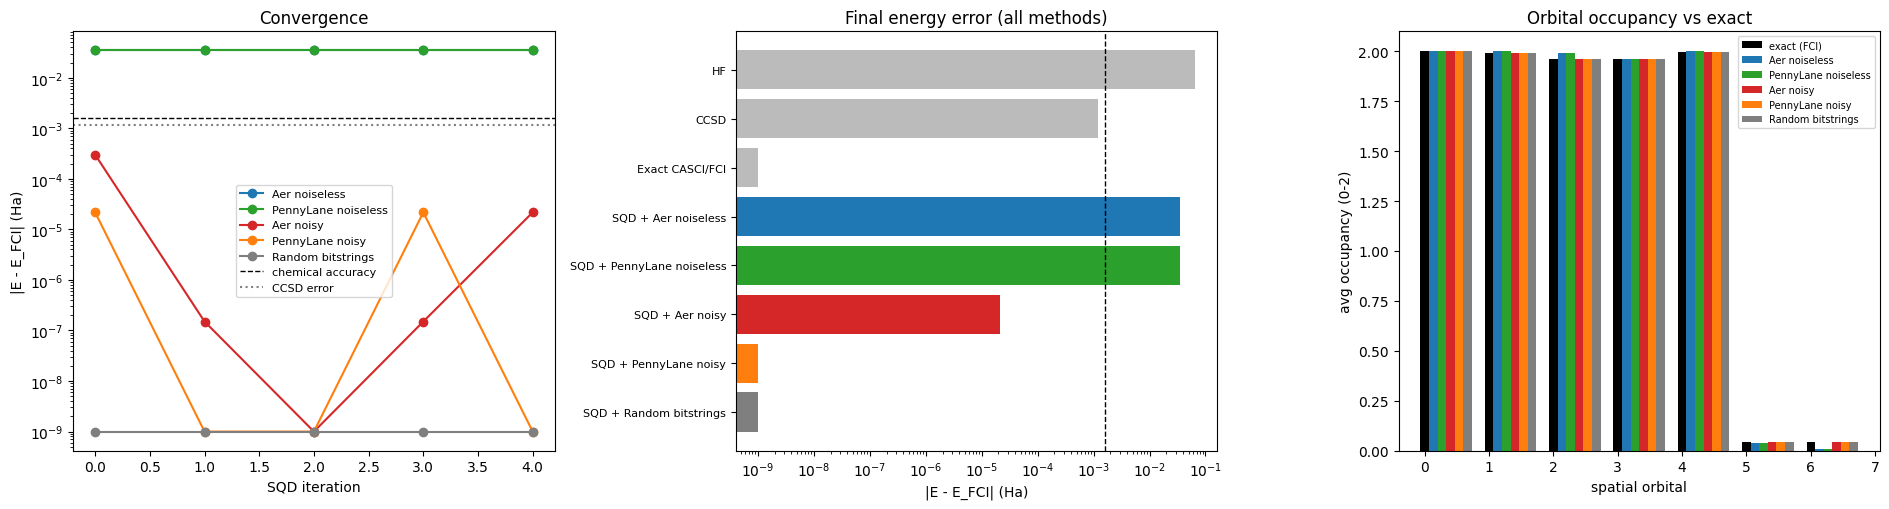

In [12]:
names = list(res); col = dict(zip(names, ["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e", "#7f7f7f"]))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for k in names:
    ax[0].plot(np.maximum(t_iter[k].values, 1e-9), marker="o", label=k, color=col[k])
ax[0].axhline(CHEM, color="k", ls="--", lw=1, label="chemical accuracy"); ax[0].axhline(abs(ccsd.e_tot - exact_energy), color="gray", ls=":", label="CCSD error")
ax[0].set(yscale="log", xlabel="SQD iteration", ylabel="|E - E_FCI| (Ha)", title="Convergence"); ax[0].legend(fontsize=8)

lab = list(t_energy["Method"]); err = np.maximum(t_energy["Error vs FCI (Ha)"].values, 1e-9)
cols = ["#bbb"] * 3 + [col[k] for k in names]
ax[1].barh(range(len(lab)), err, color=cols); ax[1].set_yticks(range(len(lab))); ax[1].set_yticklabels(lab, fontsize=8)
ax[1].axvline(CHEM, color="k", ls="--", lw=1); ax[1].set(xscale="log", xlabel="|E - E_FCI| (Ha)", title="Final energy error (all methods)"); ax[1].invert_yaxis()

w = 0.8 / (len(names) + 1); x = np.arange(norb)
ax[2].bar(x, exact_occ, w, color="k", label="exact (FCI)")
for i, k in enumerate(names): ax[2].bar(x + (i + 1) * w, res[k]["occ"], w, color=col[k], label=k)
ax[2].set(xlabel="spatial orbital", ylabel="avg occupancy (0-2)", title="Orbital occupancy vs exact"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig1_accuracy.png", dpi=140); plt.show()

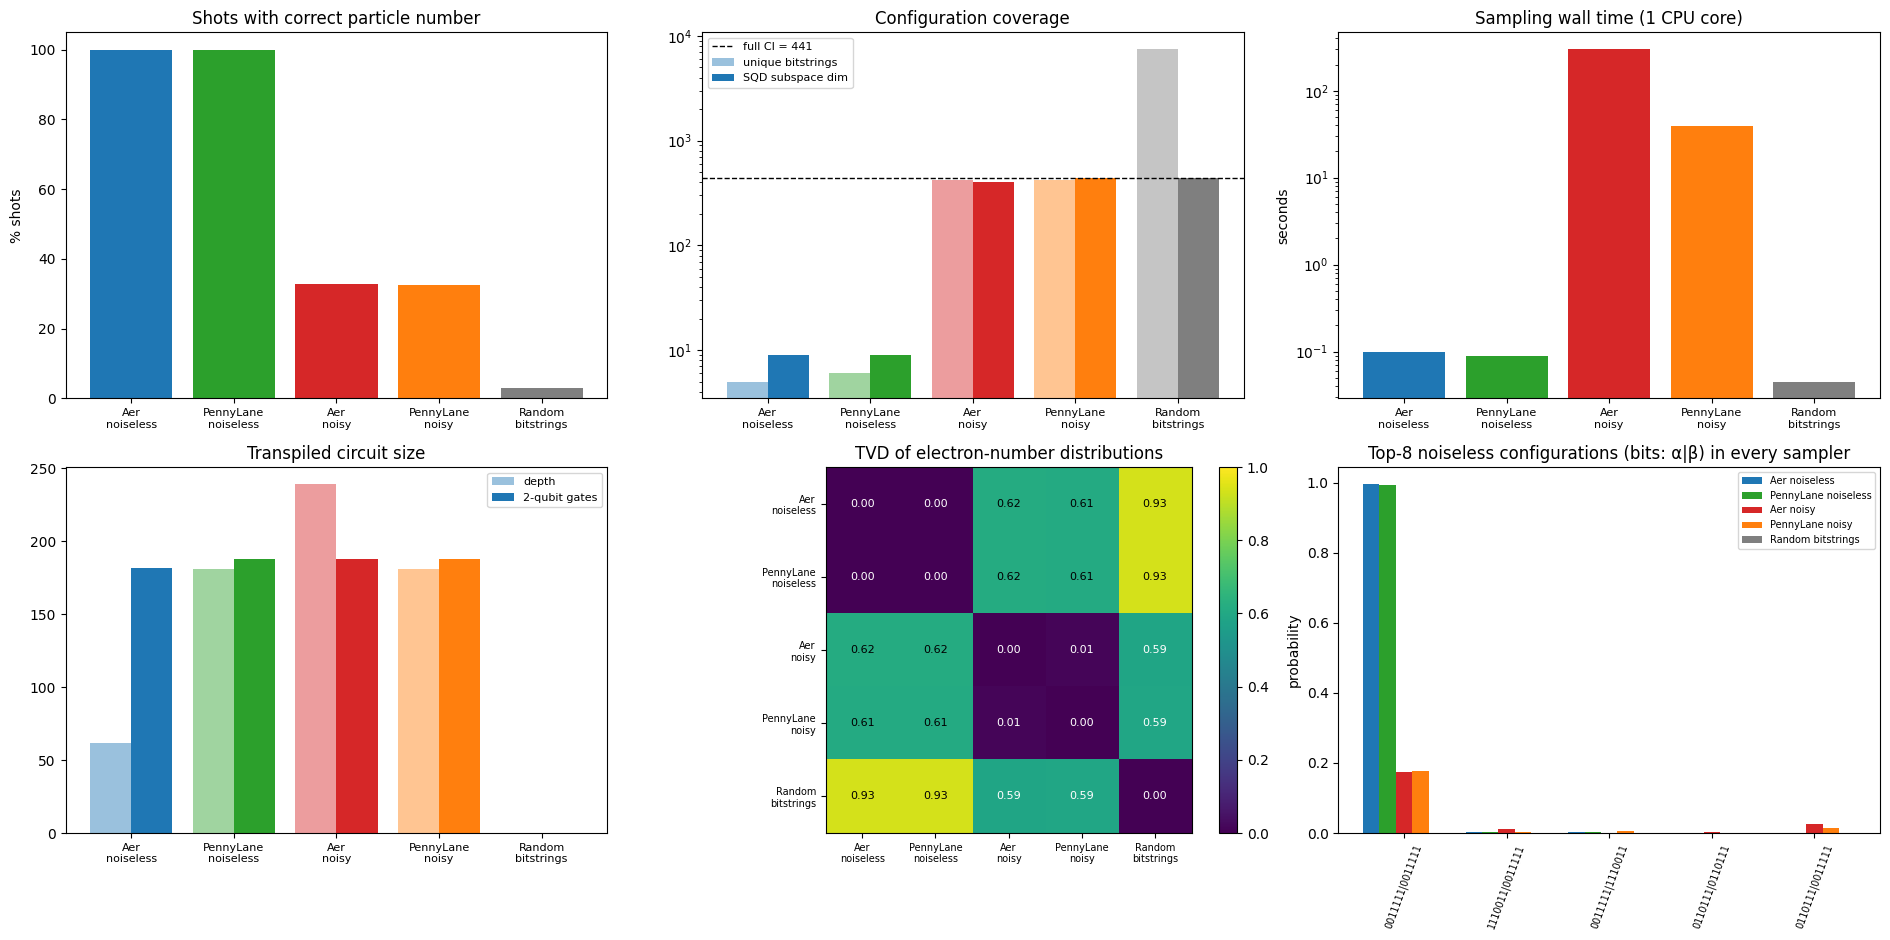

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(19, 9.5))
ax = ax.ravel(); x = np.arange(len(names)); cc = [col[k] for k in names]; short = [k.replace(" ", "\n", 1) for k in names]
ax[0].bar(x, [res[k]["valid"] * 100 for k in names], color=cc); ax[0].set(ylabel="% shots", title="Shots with correct particle number")
ax[1].bar(x - 0.2, [res[k]["unique"] for k in names], 0.4, color=cc, alpha=.45, label="unique bitstrings")
ax[1].bar(x + 0.2, [res[k]["dim"] for k in names], 0.4, color=cc, label="SQD subspace dim")
ax[1].axhline(full_ci, color="k", ls="--", lw=1, label=f"full CI = {full_ci}"); ax[1].set(yscale="log", title="Configuration coverage"); ax[1].legend(fontsize=8)
ax[2].bar(x, [max(meta_d[k]["time"], 1e-3) for k in names], color=cc); ax[2].set(yscale="log", ylabel="seconds", title="Sampling wall time (1 CPU core)")
ax[3].bar(x - 0.2, [meta_d[k]["depth"] for k in names], 0.4, color=cc, alpha=.45, label="depth")
ax[3].bar(x + 0.2, [meta_d[k]["two_q"] for k in names], 0.4, color=cc, label="2-qubit gates"); ax[3].set(title="Transpiled circuit size"); ax[3].legend(fontsize=8)
for a in ax[:4]: a.set_xticks(x); a.set_xticklabels(short, fontsize=8)

# distance between samplers measured on a low-dimensional statistic: total electron-number distribution
def popdist(c):
    h = np.zeros(nq + 1)
    for b, v in c.items(): h[b.count("1")] += v
    return h / h.sum()
P = {k: popdist(counts_d[k]) for k in names}
tvd = np.array([[0.5 * np.abs(P[a] - P[b]).sum() for b in names] for a in names])
im = ax[4].imshow(tvd, vmin=0, vmax=1, cmap="viridis")
ax[4].set_xticks(x); ax[4].set_yticks(x); ax[4].set_xticklabels(short, fontsize=7); ax[4].set_yticklabels(short, fontsize=7)
for i in range(len(names)):
    for j in range(len(names)): ax[4].text(j, i, f"{tvd[i,j]:.2f}", ha="center", va="center", color="w" if tvd[i,j] < .6 else "k", fontsize=8)
ax[4].set_title("TVD of electron-number distributions"); plt.colorbar(im, ax=ax[4], fraction=.046)
def dist(c):
    tot = sum(c.values()); return {k: v / tot for k, v in c.items()}
D = {k: dist(counts_d[k]) for k in names}

top = sorted(D["Aer noiseless"].items(), key=lambda kv: -kv[1])[:8]
for i, k in enumerate(names): ax[5].bar(np.arange(len(top)) + i * 0.16, [D[k].get(s, 0) for s, _ in top], 0.16, color=col[k], label=k)
ax[5].set_xticks(np.arange(len(top)) + 0.32); ax[5].set_xticklabels([s[-norb:] + "|" + s[:norb] for s, _ in top], rotation=70, fontsize=7)
ax[5].set(ylabel="probability", title="Top-8 noiseless configurations (bits: α|β) in every sampler"); ax[5].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig2_sampler_diagnostics.png", dpi=140); plt.show()

In [ ]:
# agreement checks between the two implementations
cfg_tvd = 0.5 * sum(abs(D["Aer noiseless"].get(k, 0) - D["PennyLane noiseless"].get(k, 0)) for k in set(D["Aer noiseless"]) | set(D["PennyLane noiseless"]))
print(f"Noiseless Aer vs PennyLane, TVD over full bitstring distributions : {cfg_tvd:.3f}  (should be ~0: same physics, shot noise only)")
print(f"Noisy Aer vs PennyLane, TVD of electron-number distributions      : {tvd[names.index('Aer noisy'), names.index('PennyLane noisy')]:.3f}  (different noise models)")

Noiseless Aer vs PennyLane, TVD over full bitstring distributions : 0.002  (should be ~0: same physics, shot noise only)
Noisy Aer vs PennyLane, TVD of electron-number distributions      : 0.045  (different noise models)
